# C. Mathematical Reference

This appendix collects the formulas used most often in the book: trigonometric identities, series, integrals, Fourier series, transform pairs and properties, convolution rules, probability formulas and decibel conversions. It is meant to be consulted rather than read, and each table states its conventions at the top, because a factor of $2\pi$ or a sign in an exponent is the most common source of error when formulas are copied from one book into another.

I have checked every formula that can be checked numerically. The code cells below each group of tables evaluate both sides of each identity or transform pair (by direct summation, numerical integration, the FFT or simulation) and stop with an error if any disagreement exceeds a tight tolerance. The first check is shown in full as an example of the method; the others are hidden but can be expanded. Pairs involving impulses, such as $\cos(\omega_0 t) \leftrightarrow \pi[\delta(\omega - \omega_0) + \delta(\omega + \omega_0)]$, cannot be evaluated pointwise and are not checked numerically; they follow from the others by the limiting arguments given in Chapter 8.

In [1]:
from math import factorial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import integrate, signal, special

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
rng = np.random.default_rng(42)

RESULTS = []


def check(group, name, lhs, rhs, tol=1e-9):
    """Record the largest absolute difference between two expressions; fail if above tol."""
    err = float(np.max(np.abs(np.asarray(lhs) - np.asarray(rhs))))
    assert err <= tol, f"{group} / {name}: error {err:.2e} exceeds {tol:.0e}"
    RESULTS.append((group, name, err, tol))


def summarize(group):
    """Print how many formulas of a group were checked and the largest error."""
    errs = [e for g, _, e, _ in RESULTS if g == group]
    print(f"{group}: {len(errs)} formulas checked, largest absolute error {max(errs):.1e}")

## C.1 Notation and Conventions

The book uses the following notation throughout.

| Quantity | Symbol |
|---|---|
| Continuous time (s), discrete index | $t$, $n$ |
| Continuous / discrete signals | $x(t)$, $x[n]$ |
| Sampling rate (Hz), sampling period (s) | $f_s$, $T_s = 1/f_s$ |
| Frequency in Hz | $f$ |
| Continuous-time angular frequency (rad/s) | $\omega = 2\pi f$ |
| Discrete-time angular frequency (rad/sample) | $\Omega = \omega T_s = 2\pi f/f_s$ |
| Imaginary unit | $j$ (never $i$) |
| Complex conjugate | $z^*$ |
| Continuous-time Fourier transform | $X(\omega)$ or $X(f)$ (state which) |
| DTFT | $X(e^{j\Omega})$ |
| DFT | $X[k]$, length $N$, bin frequency $f_k = k f_s / N$ |
| Laplace / z-transform | $X(s)$, $X(z)$ |
| Impulse response, transfer function, frequency response | $h$, $H(s)$ / $H(z)$, $H(\omega)$ or $H(e^{j\Omega})$ |
| Convolution | $y = x * h$; $y[n] = \sum_k x[k]\,h[n-k]$ |
| Unit impulse / unit step | $\delta(t)$, $\delta[n]$ / $u(t)$, $u[n]$ |
| Expectation, variance | $\mathbb{E}[\cdot]$, $\sigma^2$ |
| Autocorrelation (process / estimate) | $R_x(\tau)$ or $R_x[k]$ / $\hat{r}_x[k]$ |
| Power spectral density (true / estimate) | $S_x(f)$ / $\hat{S}_x(f)$ |
| Vectors, matrices | $\mathbf{x}$, $\mathbf{A}$ |
| Decibels | amplitude ratio $20\log_{10}$, power ratio $10\log_{10}$ |

Physiological units: ECG in mV, EEG in µV, surface EMG in mV (or µV for small signals), PPG in arbitrary units (a.u.), blood pressure in mmHg, time in s or ms, frequency in Hz.

The elementary functions that appear in the transform tables are defined as follows. Note that $\operatorname{sinc}$ is the *normalized* sinc function, the same convention as `np.sinc`.

| Function | Definition |
|---|---|
| Unit step | $u(t) = 1$ for $t > 0$, $0$ for $t < 0$; $\quad u[n] = 1$ for $n \ge 0$, $0$ otherwise |
| Unit impulse | $\delta[n] = 1$ for $n = 0$, $0$ otherwise; $\quad \delta(t)$: $\int_{-\infty}^{\infty} \delta(t)\,g(t)\,dt = g(0)$ for continuous $g$ |
| Sign | $\operatorname{sgn}(t) = 1$ for $t > 0$, $-1$ for $t < 0$ |
| Rectangle | $\operatorname{rect}(t) = 1$ for $\lvert t\rvert < 1/2$, $0$ for $\lvert t\rvert > 1/2$ |
| Triangle | $\Lambda(t) = 1 - \lvert t\rvert$ for $\lvert t\rvert < 1$, $0$ otherwise |
| Normalized sinc | $\operatorname{sinc}(x) = \dfrac{\sin(\pi x)}{\pi x}$, $\operatorname{sinc}(0) = 1$ |
| Modulo index | $((n))_N = n \bmod N$, the remainder in $\{0, 1, \ldots, N-1\}$ |

## C.2 Trigonometric Identities and Euler's Formula

### Basic identities

$$
\begin{aligned}
&\sin^2\theta + \cos^2\theta = 1, \qquad \sin(-\theta) = -\sin\theta, \qquad \cos(-\theta) = \cos\theta,\\
&\sin\theta = \cos(\theta - \pi/2), \qquad \cos(\theta \pm \pi) = -\cos\theta, \qquad \sin(\theta \pm \pi) = -\sin\theta .
\end{aligned}
$$

### Sum and difference of angles

$$
\begin{aligned}
\cos(\alpha \pm \beta) &= \cos\alpha\cos\beta \mp \sin\alpha\sin\beta,\\
\sin(\alpha \pm \beta) &= \sin\alpha\cos\beta \pm \cos\alpha\sin\beta .
\end{aligned}
$$

### Double angle and power reduction

$$
\begin{aligned}
\cos 2\theta &= \cos^2\theta - \sin^2\theta = 2\cos^2\theta - 1 = 1 - 2\sin^2\theta, \qquad \sin 2\theta = 2\sin\theta\cos\theta,\\
\cos^2\theta &= \tfrac{1}{2}(1 + \cos 2\theta), \qquad \sin^2\theta = \tfrac{1}{2}(1 - \cos 2\theta).
\end{aligned}
$$

### Product to sum

$$
\begin{aligned}
\cos\alpha\cos\beta &= \tfrac{1}{2}\left[\cos(\alpha - \beta) + \cos(\alpha + \beta)\right],\\
\sin\alpha\sin\beta &= \tfrac{1}{2}\left[\cos(\alpha - \beta) - \cos(\alpha + \beta)\right],\\
\sin\alpha\cos\beta &= \tfrac{1}{2}\left[\sin(\alpha + \beta) + \sin(\alpha - \beta)\right].
\end{aligned}
$$

### Sum to product

$$
\begin{aligned}
\cos\alpha + \cos\beta &= 2\cos\tfrac{\alpha + \beta}{2}\cos\tfrac{\alpha - \beta}{2}, &
\cos\alpha - \cos\beta &= -2\sin\tfrac{\alpha + \beta}{2}\sin\tfrac{\alpha - \beta}{2},\\
\sin\alpha + \sin\beta &= 2\sin\tfrac{\alpha + \beta}{2}\cos\tfrac{\alpha - \beta}{2}, &
\sin\alpha - \sin\beta &= 2\cos\tfrac{\alpha + \beta}{2}\sin\tfrac{\alpha - \beta}{2}.
\end{aligned}
$$

### Combining a cosine and a sine of the same frequency

For real $a$ and $b$,

$$
a\cos\theta + b\sin\theta = R\cos(\theta - \varphi), \qquad R = \sqrt{a^2 + b^2}, \qquad \varphi = \operatorname{atan2}(b, a).
$$

For example, $3\cos\theta + 4\sin\theta = 5\cos(\theta - 0.9273)$, with $0.9273$ rad $= 53.13°$ ([Section 2.2](../ch02_math_toolkit/index.md)).

### Euler's formula and complex numbers

$$
\begin{aligned}
e^{j\theta} &= \cos\theta + j\sin\theta, \qquad
\cos\theta = \frac{e^{j\theta} + e^{-j\theta}}{2}, \qquad
\sin\theta = \frac{e^{j\theta} - e^{-j\theta}}{2j},\\
\left(e^{j\theta}\right)^n &= e^{jn\theta} = \cos n\theta + j\sin n\theta \quad \text{(De Moivre)}, \qquad
e^{j\pi} = -1, \quad e^{\pm j\pi/2} = \pm j, \quad e^{j2\pi k} = 1 \;\; (k \in \mathbb{Z}),\\
1 - e^{j\theta} &= -2j\,e^{j\theta/2}\sin(\theta/2).
\end{aligned}
$$

For $z = a + jb = r e^{j\theta}$:

$$
\begin{aligned}
&r = \lvert z\rvert = \sqrt{a^2 + b^2} = \sqrt{z z^*}, \qquad \theta = \arg z = \operatorname{atan2}(b, a), \qquad z^* = a - jb = r e^{-j\theta},\\
&\operatorname{Re}\{z\} = \frac{z + z^*}{2}, \qquad \operatorname{Im}\{z\} = \frac{z - z^*}{2j}, \qquad \frac{1}{z} = \frac{z^*}{\lvert z\rvert^2}, \qquad z_1 z_2 = r_1 r_2\, e^{j(\theta_1 + \theta_2)} .
\end{aligned}
$$

The cell below evaluates every identity of this subsection at 2000 random angles.

In [2]:
g = "Trigonometry and Euler"
a, b = rng.uniform(-np.pi, np.pi, (2, 2000))
check(g, "Pythagoras", np.sin(a)**2 + np.cos(a)**2, 1)
check(g, "shift by -pi/2", np.sin(a), np.cos(a - np.pi / 2))
check(g, "cos(a+b)", np.cos(a + b), np.cos(a) * np.cos(b) - np.sin(a) * np.sin(b))
check(g, "cos(a-b)", np.cos(a - b), np.cos(a) * np.cos(b) + np.sin(a) * np.sin(b))
check(g, "sin(a+b)", np.sin(a + b), np.sin(a) * np.cos(b) + np.cos(a) * np.sin(b))
check(g, "sin(a-b)", np.sin(a - b), np.sin(a) * np.cos(b) - np.cos(a) * np.sin(b))
check(g, "cos 2a", np.cos(2 * a), 1 - 2 * np.sin(a)**2)
check(g, "sin 2a", np.sin(2 * a), 2 * np.sin(a) * np.cos(a))
check(g, "cos^2", np.cos(a)**2, (1 + np.cos(2 * a)) / 2)
check(g, "cos cos", np.cos(a) * np.cos(b), (np.cos(a - b) + np.cos(a + b)) / 2)
check(g, "sin sin", np.sin(a) * np.sin(b), (np.cos(a - b) - np.cos(a + b)) / 2)
check(g, "sin cos", np.sin(a) * np.cos(b), (np.sin(a + b) + np.sin(a - b)) / 2)
s, d = (a + b) / 2, (a - b) / 2
check(g, "cos + cos", np.cos(a) + np.cos(b), 2 * np.cos(s) * np.cos(d))
check(g, "cos - cos", np.cos(a) - np.cos(b), -2 * np.sin(s) * np.sin(d))
check(g, "sin + sin", np.sin(a) + np.sin(b), 2 * np.sin(s) * np.cos(d))
check(g, "sin - sin", np.sin(a) - np.sin(b), 2 * np.cos(s) * np.sin(d))
A, B = rng.normal(size=(2, 2000))
check(g, "a cos + b sin", A * np.cos(a) + B * np.sin(a), np.hypot(A, B) * np.cos(a - np.arctan2(B, A)))
check(g, "Euler", np.exp(1j * a), np.cos(a) + 1j * np.sin(a))
check(g, "cos via exp", np.cos(a), (np.exp(1j * a) + np.exp(-1j * a)) / 2)
check(g, "sin via exp", np.sin(a), (np.exp(1j * a) - np.exp(-1j * a)) / 2j)
check(g, "De Moivre n=5", (np.cos(a) + 1j * np.sin(a))**5, np.cos(5 * a) + 1j * np.sin(5 * a))
check(g, "1 - e^(j theta)", 1 - np.exp(1j * a), -2j * np.exp(1j * a / 2) * np.sin(a / 2))
z = A + 1j * B
check(g, "Re, Im, 1/z", [(z + z.conj()) / 2 - A, (z - z.conj()) / 2j - B, 1 / z - z.conj() / np.abs(z)**2], 0)
check(g, "3 cos + 4 sin example", [np.hypot(3, 4), np.arctan2(4, 3)], [5, 0.9272952180016122])
summarize(g)

Trigonometry and Euler: 24 formulas checked, largest absolute error 7.9e-15


## C.3 Series and Sums

### Geometric series

For any complex $a \ne 1$,

$$
\sum_{n=0}^{N-1} a^n = \frac{1 - a^N}{1 - a}, \qquad
\sum_{n=N_1}^{N_2} a^n = \frac{a^{N_1} - a^{N_2 + 1}}{1 - a},
$$

and the first sum equals $N$ when $a = 1$. For $\lvert a\rvert < 1$ the infinite sums converge:

$$
\sum_{n=0}^{\infty} a^n = \frac{1}{1 - a}, \qquad
\sum_{n=0}^{\infty} n\,a^n = \frac{a}{(1 - a)^2}, \qquad
\sum_{n=0}^{\infty} (n+1)\,a^n = \frac{1}{(1 - a)^2}.
$$

### Sums of complex exponentials

Setting $a = e^{-j\Omega}$ in the finite geometric series and factoring out half-angle exponentials gives the **Dirichlet kernel**, which describes the spectrum of a rectangular window:

$$
\sum_{n=0}^{N-1} e^{-j\Omega n} = e^{-j\Omega (N-1)/2}\,\frac{\sin(N\Omega/2)}{\sin(\Omega/2)} .
$$

The $N$-th roots of unity sum to zero unless the exponent is a multiple of $2\pi$:

$$
\sum_{n=0}^{N-1} e^{j2\pi k n/N} = \begin{cases} N, & k = 0, \pm N, \pm 2N, \ldots \\ 0, & \text{otherwise.} \end{cases}
$$

### Power sums

$$
\sum_{n=1}^{N} n = \frac{N(N+1)}{2}, \qquad
\sum_{n=1}^{N} n^2 = \frac{N(N+1)(2N+1)}{6}, \qquad
\sum_{n=1}^{N} n^3 = \left[\frac{N(N+1)}{2}\right]^2 .
$$

### Taylor series

Around $x = a$, $f(x) = \sum_{k=0}^{\infty} \frac{f^{(k)}(a)}{k!}(x - a)^k$, and the series used most often are

| Function | Series | Converges for |
|---|---|---|
| $e^x$ | $1 + x + \frac{x^2}{2!} + \frac{x^3}{3!} + \cdots = \sum_{k \ge 0} \frac{x^k}{k!}$ | all $x$ (also complex) |
| $\sin x$ | $x - \frac{x^3}{3!} + \frac{x^5}{5!} - \cdots$ | all $x$ |
| $\cos x$ | $1 - \frac{x^2}{2!} + \frac{x^4}{4!} - \cdots$ | all $x$ |
| $\ln(1 + x)$ | $x - \frac{x^2}{2} + \frac{x^3}{3} - \cdots = \sum_{k \ge 1} \frac{(-1)^{k+1} x^k}{k}$ | $-1 < x \le 1$ |
| $\frac{1}{1 - x}$ | $1 + x + x^2 + \cdots$ | $\lvert x\rvert < 1$ |
| $(1 + x)^\alpha$ | $1 + \alpha x + \frac{\alpha(\alpha - 1)}{2!}x^2 + \cdots = \sum_{k \ge 0}\binom{\alpha}{k} x^k$ | $\lvert x\rvert < 1$ |

The first-order truncations give the small-signal approximations $e^x \approx 1 + x$, $\sin x \approx x$, $\cos x \approx 1 - x^2/2$, $\ln(1 + x) \approx x$ and $(1 + x)^\alpha \approx 1 + \alpha x$, used for linearization in [Section 2.3](../ch02_math_toolkit/index.md).

In [3]:
g = "Series and sums"
N, N1, N2 = 17, 3, 25
for a in [0.7 * np.exp(0.4j), 1.3 * np.exp(-2.1j), -0.95]:
    n = np.arange(N)
    check(g, "finite geometric", np.sum(a**n), (1 - a**N) / (1 - a))
    check(g, "geometric N1..N2", np.sum(a**np.arange(N1, N2 + 1)), (a**N1 - a**(N2 + 1)) / (1 - a), tol=1e-7)
for a in [0.7 * np.exp(0.4j), -0.5, 0.9]:
    n = np.arange(2000)
    check(g, "infinite geometric", np.sum(a**n), 1 / (1 - a))
    check(g, "sum n a^n", np.sum(n * a**n), a / (1 - a)**2)
    check(g, "sum (n+1) a^n", np.sum((n + 1) * a**n), 1 / (1 - a)**2)
W = np.linspace(0.01, 3.1, 50)
n = np.arange(N)
dirichlet = np.exp(-1j * W * (N - 1) / 2) * np.sin(N * W / 2) / np.sin(W / 2)
check(g, "Dirichlet kernel", np.exp(-1j * np.outer(W, n)).sum(axis=1), dirichlet)
roots = [np.sum(np.exp(2j * np.pi * k * n / N)) for k in range(-2 * N, 2 * N + 1)]
check(g, "roots of unity", roots, [N if k % N == 0 else 0 for k in range(-2 * N, 2 * N + 1)])
k = np.arange(1, 101)
check(g, "power sums", [k.sum(), (k**2).sum(), (k**3).sum()],
      [100 * 101 / 2, 100 * 101 * 201 / 6, (100 * 101 / 2)**2])
x, alpha, kk = 0.5, -1.5, np.arange(60)
check(g, "Taylor exp", np.sum(x**kk / np.array([factorial(int(i)) for i in kk], float)), np.exp(x))
check(g, "Taylor sin, cos", [sum((-1)**i * x**(2 * i + 1) / factorial(2 * i + 1) for i in range(20)),
                             sum((-1)**i * x**(2 * i) / factorial(2 * i) for i in range(20))],
      [np.sin(x), np.cos(x)])
check(g, "Taylor ln(1+x)", np.sum((-1.0)**(kk[1:] + 1) * x**kk[1:] / kk[1:]), np.log1p(x))
check(g, "binomial series", np.sum(special.binom(alpha, kk) * x**kk), (1 + x)**alpha)
summarize(g)

Series and sums: 22 formulas checked, largest absolute error 4.3e-14


## C.4 Useful Integrals

### Exponentials and polynomials times exponentials

For complex $a \ne 0$ (constants of integration omitted),

$$
\int e^{at}\,dt = \frac{e^{at}}{a}, \qquad
\int t\,e^{at}\,dt = e^{at}\left(\frac{t}{a} - \frac{1}{a^2}\right),
$$

and for $\operatorname{Re}\{a\} > 0$ and integer $n \ge 0$,

$$
\int_0^{\infty} e^{-at}\,dt = \frac{1}{a}, \qquad
\int_0^{\infty} t^n e^{-at}\,dt = \frac{n!}{a^{n+1}} .
$$

### Exponentials times sinusoids

$$
\begin{aligned}
\int e^{at}\cos(bt)\,dt &= \frac{e^{at}\left(a\cos bt + b\sin bt\right)}{a^2 + b^2}, &
\int e^{at}\sin(bt)\,dt &= \frac{e^{at}\left(a\sin bt - b\cos bt\right)}{a^2 + b^2},\\
\int_0^{\infty} e^{-at}\cos(bt)\,dt &= \frac{a}{a^2 + b^2}, &
\int_0^{\infty} e^{-at}\sin(bt)\,dt &= \frac{b}{a^2 + b^2} \quad (a > 0).
\end{aligned}
$$

### Gaussian integrals

For $a > 0$ and $\sigma > 0$ (derived in [Section 2.3](../ch02_math_toolkit/index.md) with polar coordinates),

$$
\int_{-\infty}^{\infty} e^{-a t^2}\,dt = \sqrt{\frac{\pi}{a}}, \qquad
\int_{-\infty}^{\infty} e^{-t^2/(2\sigma^2)}\,dt = \sigma\sqrt{2\pi}, \qquad
\int_{-\infty}^{\infty} t^2 e^{-t^2/(2\sigma^2)}\,dt = \sigma^3\sqrt{2\pi} .
$$

### Orthogonality of sinusoids

With $\omega_0 = 2\pi/T_0$ and integers $m, n \ge 1$, over any interval of length $T_0$,

$$
\int_{T_0} \cos(m\omega_0 t)\cos(n\omega_0 t)\,dt = \int_{T_0} \sin(m\omega_0 t)\sin(n\omega_0 t)\,dt = \frac{T_0}{2}\,\delta[m - n], \qquad
\int_{T_0} \sin(m\omega_0 t)\cos(n\omega_0 t)\,dt = 0,
$$

and $\int_{T_0} e^{jm\omega_0 t}e^{-jn\omega_0 t}\,dt = T_0\,\delta[m - n]$ for all integers $m, n$.

### Other results

$$
\begin{aligned}
&\int_{-\infty}^{\infty} \frac{\sin t}{t}\,dt = \pi, \qquad \int_{-\infty}^{\infty} \operatorname{sinc}(x)\,dx = 1, \qquad
\int_{-\infty}^{\infty} \delta(t - t_0)\,g(t)\,dt = g(t_0) \;\; \text{(sifting)},\\
&\int_a^b u\,dv = \big[u v\big]_a^b - \int_a^b v\,du \;\; \text{(integration by parts)}, \qquad
\frac{d}{dt}\int_{-\infty}^{t} x(\tau)\,d\tau = x(t).
\end{aligned}
$$

In [4]:
g = "Integrals"
quad = lambda f, lo, hi, **kw: integrate.quad(f, lo, hi, limit=400, epsabs=1e-13, epsrel=1e-12, **kw)[0]
a, b, T = -1.3, 2.7, 2.0
F1 = lambda t: np.exp(a * t) * (t / a - 1 / a**2)
check(g, "int e^(at)", quad(lambda t: np.exp(a * t), 0, T), (np.exp(a * T) - 1) / a)
check(g, "int t e^(at)", quad(lambda t: t * np.exp(a * t), 0, T), F1(T) - F1(0))
for n_pow in range(5):
    check(g, "int t^n e^(-at)", quad(lambda t: t**n_pow * np.exp(-1.7 * t), 0, np.inf), factorial(n_pow) / 1.7**(n_pow + 1))
Fc = lambda t: np.exp(a * t) * (a * np.cos(b * t) + b * np.sin(b * t)) / (a**2 + b**2)
Fs = lambda t: np.exp(a * t) * (a * np.sin(b * t) - b * np.cos(b * t)) / (a**2 + b**2)
check(g, "int e^(at) cos(bt)", quad(lambda t: np.exp(a * t) * np.cos(b * t), 0, T), Fc(T) - Fc(0))
check(g, "int e^(at) sin(bt)", quad(lambda t: np.exp(a * t) * np.sin(b * t), 0, T), Fs(T) - Fs(0))
check(g, "int_0^inf e^(-at) cos", quad(lambda t: np.exp(-1.3 * t) * np.cos(b * t), 0, 60), 1.3 / (1.3**2 + b**2))
check(g, "int_0^inf e^(-at) sin", quad(lambda t: np.exp(-1.3 * t) * np.sin(b * t), 0, 60), b / (1.3**2 + b**2))
sig = 0.7
check(g, "Gaussian, a", quad(lambda t: np.exp(-2.3 * t**2), -np.inf, np.inf), np.sqrt(np.pi / 2.3))
check(g, "Gaussian, sigma", quad(lambda t: np.exp(-t**2 / (2 * sig**2)), -np.inf, np.inf), sig * np.sqrt(2 * np.pi))
check(g, "Gaussian second moment", quad(lambda t: t**2 * np.exp(-t**2 / (2 * sig**2)), -np.inf, np.inf),
      sig**3 * np.sqrt(2 * np.pi))
M, T0 = 512, 1.0
tt = np.arange(M) * T0 / M                       # uniform grid: exact for trigonometric polynomials
w0 = 2 * np.pi / T0
for m in range(1, 5):
    for n in range(0, 5):
        cc = T0 * np.mean(np.cos(m * w0 * tt) * np.cos(n * w0 * tt))
        ss = T0 * np.mean(np.sin(m * w0 * tt) * np.sin(n * w0 * tt))
        sc = T0 * np.mean(np.sin(m * w0 * tt) * np.cos(n * w0 * tt))
        ee = T0 * np.mean(np.exp(1j * m * w0 * tt) * np.exp(-1j * n * w0 * tt))
        check(g, "orthogonality", [cc, ss, sc, ee], [T0 / 2 * (m == n), T0 / 2 * (m == n), 0, T0 * (m == n)], tol=1e-12)
check(g, "int sin(t)/t", 2 * special.sici(1e9)[0], np.pi, tol=1e-8)
check(g, "int sinc", 2 * sum(quad(np.sinc, k, k + 1) for k in range(2000)) + 2 * (np.pi / 2 - special.sici(2000 * np.pi)[0]) / np.pi, 1, tol=1e-8)
eps, t0 = 1e-3, 0.4
narrow = lambda t: np.exp(-(t - t0)**2 / (2 * eps**2)) / (eps * np.sqrt(2 * np.pi))
check(g, "sifting (narrow Gaussian)", quad(lambda t: narrow(t) * np.cos(3 * t), t0 - 0.05, t0 + 0.05), np.cos(3 * t0), tol=1e-5)
check(g, "integration by parts", quad(lambda t: t * np.exp(t), 0, 1), (1 * np.e - 0) - (np.e - 1))
summarize(g)

Integrals: 38 formulas checked, largest absolute error 1.6e-06


## C.5 Fourier Series

A periodic signal $x(t) = x(t + T_0)$ with fundamental frequency $f_0 = 1/T_0$ and $\omega_0 = 2\pi/T_0$ can be written in three equivalent forms (Chapter 5). In the trigonometric form used in this book, $a_0$ is the mean value (not $a_0/2$):

$$
\begin{aligned}
x(t) &= a_0 + \sum_{k=1}^{\infty}\left[a_k\cos(k\omega_0 t) + b_k\sin(k\omega_0 t)\right], \\
a_0 &= \frac{1}{T_0}\int_{T_0} x(t)\,dt, \qquad
a_k = \frac{2}{T_0}\int_{T_0} x(t)\cos(k\omega_0 t)\,dt, \qquad
b_k = \frac{2}{T_0}\int_{T_0} x(t)\sin(k\omega_0 t)\,dt .
\end{aligned}
$$

The **compact (amplitude-phase) form** is $x(t) = a_0 + \sum_{k \ge 1} A_k\cos(k\omega_0 t + \theta_k)$ with $A_k = \sqrt{a_k^2 + b_k^2}$ and $\theta_k = \operatorname{atan2}(-b_k, a_k)$. The **complex exponential form** is

$$
x(t) = \sum_{k=-\infty}^{\infty} c_k\,e^{jk\omega_0 t}, \qquad
c_k = \frac{1}{T_0}\int_{T_0} x(t)\,e^{-jk\omega_0 t}\,dt,
$$

with $c_0 = a_0$, $c_k = (a_k - j b_k)/2$ and, for real $x(t)$, $c_{-k} = c_k^*$, so that $a_k = 2\operatorname{Re}\{c_k\}$ and $b_k = -2\operatorname{Im}\{c_k\}$. **Parseval's relation** equates the average power in the two domains:

$$
\frac{1}{T_0}\int_{T_0} \lvert x(t)\rvert^2\,dt = \sum_{k=-\infty}^{\infty} \lvert c_k\rvert^2 = a_0^2 + \frac{1}{2}\sum_{k=1}^{\infty}\left(a_k^2 + b_k^2\right).
$$

The coefficients of standard waveforms (amplitude $A$, period $T_0$, one period described on $-T_0/2 < t < T_0/2$; $k$ odd means $k = 1, 3, 5, \ldots$):

| Waveform on one period | Fourier series |
|---|---|
| Square wave: $-A$ for $t < 0$, $+A$ for $t > 0$ | $\dfrac{4A}{\pi}\sum_{k\ \text{odd}} \dfrac{\sin(k\omega_0 t)}{k}$ |
| Sawtooth: $x(t) = 2At/T_0$ | $\dfrac{2A}{\pi}\sum_{k=1}^{\infty} \dfrac{(-1)^{k+1}}{k}\sin(k\omega_0 t)$ |
| Triangle: $x(t) = A\left(1 - 4\lvert t\rvert/T_0\right)$ | $\dfrac{8A}{\pi^2}\sum_{k\ \text{odd}} \dfrac{\cos(k\omega_0 t)}{k^2}$ |
| Full-wave rectified sine: $A\lvert\sin(\pi t/T_0)\rvert$ | $\dfrac{2A}{\pi} - \dfrac{4A}{\pi}\sum_{k=1}^{\infty} \dfrac{\cos(k\omega_0 t)}{4k^2 - 1}$ |
| Pulse train: $A$ for $\lvert t\rvert < \tau/2$, else $0$ | $c_k = \dfrac{A\tau}{T_0}\operatorname{sinc}\!\left(\dfrac{k\tau}{T_0}\right)$ |
| Impulse train: $\sum_m \delta(t - mT_0)$ | $c_k = \dfrac{1}{T_0}$ for all $k$ |

In [5]:
g = "Fourier series"
T0, A, tau, M = 1.0, 1.0, 0.3, 2**16
w0 = 2 * np.pi / T0
tm = -T0 / 2 + (np.arange(M) + 0.5) * T0 / M          # midpoints of one period
kk = np.arange(1, 16)


def coeffs(x):
    """Complex Fourier coefficients c_k, k = 0..15, by the midpoint rule over one period."""
    return np.array([np.mean(x * np.exp(-1j * k * w0 * tm)) for k in range(16)])


odd = kk % 2 == 1
waves = {
    "square": (A * np.sign(tm), 0 * kk, np.where(odd, 4 * A / (np.pi * kk), 0), 0),
    "sawtooth": (2 * A * tm / T0, 0 * kk, 2 * A * (-1.0)**(kk + 1) / (np.pi * kk), 0),
    "triangle": (A * (1 - 4 * np.abs(tm) / T0), np.where(odd, 8 * A / (np.pi**2 * kk**2), 0), 0 * kk, 0),
    "rectified sine": (A * np.abs(np.sin(np.pi * tm / T0)), -4 * A / (np.pi * (4 * kk**2 - 1)), 0 * kk, 2 * A / np.pi),
}
for name, (x, a_k, b_k, a0) in waves.items():
    c = coeffs(x)
    check(g, name, np.r_[c[0].real, 2 * c[1:].real, -2 * c[1:].imag], np.r_[a0, a_k, b_k], tol=1e-4)
pulse = np.where(np.abs(tm) < tau / 2, A, 0.0)
check(g, "pulse train", coeffs(pulse), A * tau / T0 * np.sinc(np.arange(16) * tau / T0), tol=1e-4)
k_big = np.arange(1, 2_000_001, 2)
check(g, "Parseval, square wave", A**2, 0.5 * np.sum((4 * A / (np.pi * k_big))**2), tol=1e-6)
summarize(g)

Fourier series: 6 formulas checked, largest absolute error 1.2e-05


The figure shows the partial sums with harmonics up to $k = 15$ for three of the waveforms. The overshoot next to the jumps of the square and sawtooth waves is the Gibbs phenomenon of Section 5.3; the triangle, which has no jumps, converges much faster because its coefficients decay as $1/k^2$ rather than $1/k$.

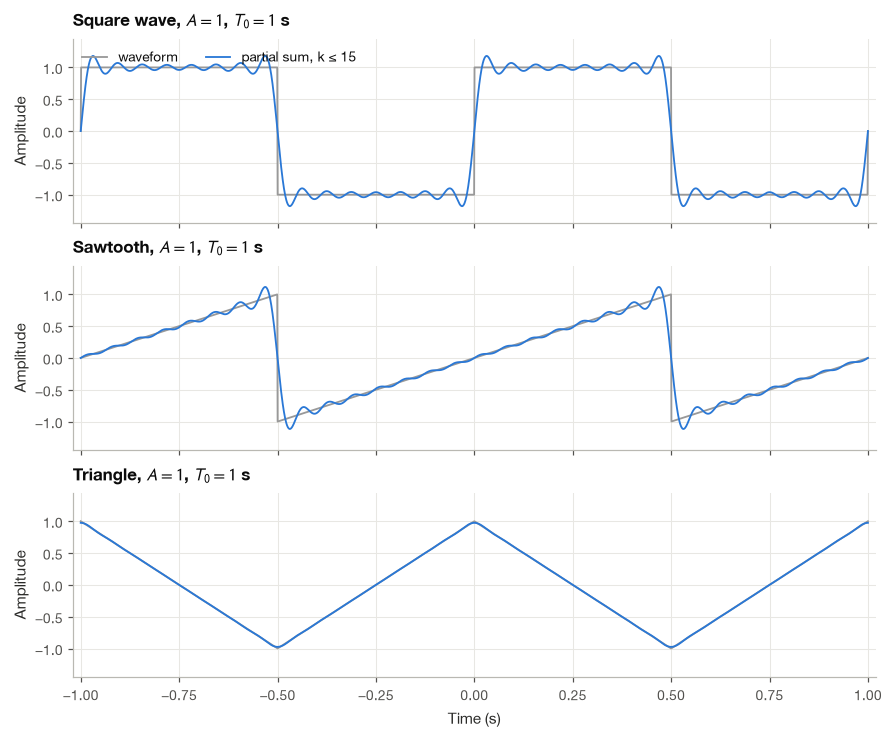

In [6]:
t = np.linspace(-1, 1, 2000)
ph = ((t + T0 / 2) % T0) - T0 / 2                       # time folded into one period
K = 15
k = np.arange(1, K + 1)
series = {
    "Square wave": (A * np.sign(ph),
                    (4 * A / np.pi) * np.sum(np.where(k % 2 == 1, 1 / k, 0)[:, None] * np.sin(np.outer(k, w0 * t)), axis=0)),
    "Sawtooth": (2 * A * ph / T0,
                 (2 * A / np.pi) * np.sum(((-1.0)**(k + 1) / k)[:, None] * np.sin(np.outer(k, w0 * t)), axis=0)),
    "Triangle": (A * (1 - 4 * np.abs(ph) / T0),
                 (8 * A / np.pi**2) * np.sum(np.where(k % 2 == 1, 1 / k**2, 0)[:, None] * np.cos(np.outer(k, w0 * t)), axis=0)),
}
fig, axes = plt.subplots(3, 1, figsize=(8, 6.6), sharex=True)
for ax, (name, (exact, partial)) in zip(axes, series.items()):
    ax.plot(t, exact, color="0.6", lw=1.2, label="waveform")
    ax.plot(t, partial, color=C[0], lw=1.2, label=f"partial sum, k ≤ {K}")
    ax.set(ylabel="Amplitude", title=f"{name}, $A = 1$, $T_0 = 1$ s", ylim=(-1.45, 1.45))
axes[0].legend(loc="upper left", ncols=2)
axes[-1].set_xlabel("Time (s)")
plt.show()

## C.6 The Continuous-Time Fourier Transform

The book uses the angular-frequency convention, with $\omega$ in rad/s:

$$
X(\omega) = \int_{-\infty}^{\infty} x(t)\,e^{-j\omega t}\,dt, \qquad
x(t) = \frac{1}{2\pi}\int_{-\infty}^{\infty} X(\omega)\,e^{j\omega t}\,d\omega .
$$

In hertz the same transform reads $X(f) = \int x(t)\,e^{-j2\pi f t}\,dt$ and $x(t) = \int X(f)\,e^{j2\pi f t}\,df$, with no $2\pi$ in front. To convert an entry of the tables below, replace $\omega$ by $2\pi f$; impulses also change scale, since $\delta(\omega - \omega_0) = \delta(f - f_0)/(2\pi)$, so that, for example, $2\pi\delta(\omega)$ becomes $\delta(f)$.

### Transform pairs

| Signal $x(t)$ | Transform $X(\omega)$ | Condition |
|---|---|---|
| $\delta(t)$ | $1$ | |
| $\delta(t - t_0)$ | $e^{-j\omega t_0}$ | |
| $1$ | $2\pi\,\delta(\omega)$ | |
| $e^{j\omega_0 t}$ | $2\pi\,\delta(\omega - \omega_0)$ | |
| $\cos(\omega_0 t)$ | $\pi\left[\delta(\omega - \omega_0) + \delta(\omega + \omega_0)\right]$ | |
| $\sin(\omega_0 t)$ | $-j\pi\left[\delta(\omega - \omega_0) - \delta(\omega + \omega_0)\right]$ | |
| $u(t)$ | $\dfrac{1}{j\omega} + \pi\,\delta(\omega)$ | |
| $\operatorname{sgn}(t)$ | $\dfrac{2}{j\omega}$ | |
| $e^{-at}u(t)$ | $\dfrac{1}{a + j\omega}$ | $\operatorname{Re}\{a\} > 0$ |
| $t\,e^{-at}u(t)$ | $\dfrac{1}{(a + j\omega)^2}$ | $\operatorname{Re}\{a\} > 0$ |
| $\dfrac{t^{n}}{n!}\,e^{-at}u(t)$ | $\dfrac{1}{(a + j\omega)^{n+1}}$ | $\operatorname{Re}\{a\} > 0$ |
| $e^{-a\lvert t\rvert}$ | $\dfrac{2a}{a^2 + \omega^2}$ | $a > 0$ |
| $e^{-at}\cos(\omega_0 t)\,u(t)$ | $\dfrac{a + j\omega}{(a + j\omega)^2 + \omega_0^2}$ | $a > 0$ |
| $e^{-at}\sin(\omega_0 t)\,u(t)$ | $\dfrac{\omega_0}{(a + j\omega)^2 + \omega_0^2}$ | $a > 0$ |
| $\operatorname{rect}(t/\tau)$ | $\tau\,\dfrac{\sin(\omega\tau/2)}{\omega\tau/2} = \tau\operatorname{sinc}\!\left(\dfrac{\omega\tau}{2\pi}\right)$ | $\tau > 0$ |
| $\Lambda(t/\tau)$ | $\tau\left[\dfrac{\sin(\omega\tau/2)}{\omega\tau/2}\right]^2$ | $\tau > 0$ |
| $\dfrac{\sin(Wt)}{\pi t}$ | $1$ for $\lvert\omega\rvert < W$, $0$ for $\lvert\omega\rvert > W$ | $W > 0$ |
| $e^{-t^2/(2\sigma^2)}$ | $\sigma\sqrt{2\pi}\;e^{-\sigma^2\omega^2/2}$ | $\sigma > 0$ |
| $\sum_{m} \delta(t - mT)$ | $\dfrac{2\pi}{T}\sum_{k} \delta\!\left(\omega - \dfrac{2\pi k}{T}\right)$ | |

### Properties

| Property | Signal | Transform |
|---|---|---|
| Linearity | $a\,x(t) + b\,y(t)$ | $a\,X(\omega) + b\,Y(\omega)$ |
| Time shift | $x(t - t_0)$ | $e^{-j\omega t_0}X(\omega)$ |
| Frequency shift | $e^{j\omega_0 t}x(t)$ | $X(\omega - \omega_0)$ |
| Modulation | $x(t)\cos(\omega_0 t)$ | $\frac{1}{2}\left[X(\omega - \omega_0) + X(\omega + \omega_0)\right]$ |
| Time scaling | $x(at)$, $a \ne 0$ real | $\frac{1}{\lvert a\rvert}X(\omega/a)$ |
| Time reversal | $x(-t)$ | $X(-\omega)$ |
| Conjugation | $x^*(t)$ | $X^*(-\omega)$ |
| Real signal | $x(t)$ real | $X(-\omega) = X^*(\omega)$; $\lvert X\rvert$ even, $\angle X$ odd |
| Real and even / real and odd | $x(t)$ | $X(\omega)$ real and even / imaginary and odd |
| Differentiation | $\dfrac{d^n x}{dt^n}$ | $(j\omega)^n X(\omega)$ |
| Multiplication by $t$ | $t\,x(t)$ | $j\,\dfrac{dX}{d\omega}$ |
| Integration | $\int_{-\infty}^{t} x(\tau)\,d\tau$ | $\dfrac{X(\omega)}{j\omega} + \pi X(0)\,\delta(\omega)$ |
| Convolution | $x(t) * h(t)$ | $X(\omega)\,H(\omega)$ |
| Multiplication | $x(t)\,y(t)$ | $\frac{1}{2\pi}\,X(\omega) * Y(\omega)$ |
| Duality | $X(t)$ | $2\pi\,x(-\omega)$ |
| Area and value at zero | $X(0) = \int x(t)\,dt$ | $x(0) = \frac{1}{2\pi}\int X(\omega)\,d\omega$ |
| Parseval | $\int \lvert x(t)\rvert^2 dt$ | $= \frac{1}{2\pi}\int \lvert X(\omega)\rvert^2 d\omega = \int \lvert X(f)\rvert^2 df$ |

In [7]:
g = "Fourier transform"


def ctft(x, w, lo, hi, points=None):
    """X(w) = integral of x(t) exp(-j w t) over [lo, hi], by adaptive quadrature."""
    kw = dict(limit=400, epsabs=1e-12, epsrel=1e-11, points=points)
    re = integrate.quad(lambda t: x(t) * np.cos(w * t), lo, hi, **kw)[0]
    im = integrate.quad(lambda t: -x(t) * np.sin(w * t), lo, hi, **kw)[0]
    return re + 1j * im


ws = np.array([0.0, 0.3, 1.7, 4.2])
a, w0, tau, sig = 1.5, 3.0, 2.0, 0.7
pairs = {
    "e^(-at)u(t)": (lambda t: np.exp(-a * t), 0, 40, None, lambda w: 1 / (a + 1j * w)),
    "t e^(-at)u(t)": (lambda t: t * np.exp(-a * t), 0, 40, None, lambda w: 1 / (a + 1j * w)**2),
    "t^3/3! e^(-at)u(t)": (lambda t: t**3 / 6 * np.exp(-a * t), 0, 60, None, lambda w: 1 / (a + 1j * w)**4),
    "e^(-a|t|)": (lambda t: np.exp(-a * np.abs(t)), -40, 40, [0], lambda w: 2 * a / (a**2 + w**2)),
    "damped cos": (lambda t: np.exp(-a * t) * np.cos(w0 * t), 0, 40, None,
                   lambda w: (a + 1j * w) / ((a + 1j * w)**2 + w0**2)),
    "damped sin": (lambda t: np.exp(-a * t) * np.sin(w0 * t), 0, 40, None,
                   lambda w: w0 / ((a + 1j * w)**2 + w0**2)),
    "rect(t/tau)": (lambda t: 1.0, -tau / 2, tau / 2, None, lambda w: tau * np.sinc(w * tau / (2 * np.pi))),
    "triangle(t/tau)": (lambda t: 1 - np.abs(t) / tau, -tau, tau, [0], lambda w: tau * np.sinc(w * tau / (2 * np.pi))**2),
    "Gaussian": (lambda t: np.exp(-t**2 / (2 * sig**2)), -12, 12, None,
                 lambda w: sig * np.sqrt(2 * np.pi) * np.exp(-sig**2 * w**2 / 2)),
}
for name, (x, lo, hi, pts, X) in pairs.items():
    check(g, name, [ctft(x, w, lo, hi, pts) for w in ws], X(ws), tol=1e-8)

Wc = 2.0
for t_ in (0.4, 1.3):        # sin(Wt)/(pi t) from the inverse transform of an ideal low-pass spectrum
    check(g, "ideal low-pass pair", integrate.quad(lambda w: np.cos(w * t_), -Wc, Wc)[0] / (2 * np.pi),
          np.sin(Wc * t_) / (np.pi * t_))

x = lambda t: np.exp(-t**2 / 2) * (1 + 0.5 * t)                  # smooth, asymmetric test signal
dx = lambda t: np.exp(-t**2 / 2) * (0.5 - t - 0.5 * t**2)
X = lambda w: ctft(x, w, -14, 14)
t0, w_mod, s_fac, h = 0.8, 3.0, -2.0, 1e-3
for w in (0.0, 0.9, 2.5):
    check(g, "time shift", ctft(lambda t: x(t - t0), w, -14, 16), np.exp(-1j * w * t0) * X(w))
    check(g, "modulation", ctft(lambda t: x(t) * np.cos(w_mod * t), w, -14, 14), (X(w - w_mod) + X(w + w_mod)) / 2)
    check(g, "time scaling (a = -2)", ctft(lambda t: x(s_fac * t), w, -8, 8), X(w / s_fac) / abs(s_fac))
    check(g, "time reversal", ctft(lambda t: x(-t), w, -14, 14), X(-w))
    check(g, "differentiation", ctft(dx, w, -14, 14), 1j * w * X(w))
    check(g, "multiplication by t", ctft(lambda t: t * x(t), w, -14, 14), 1j * (X(w + h) - X(w - h)) / (2 * h), tol=1e-6)
    check(g, "real signal symmetry", X(-w), np.conj(X(w)))
s1, s2 = 0.6, 0.8
s12 = np.hypot(s1, s2)
conv = lambda t: np.sqrt(2 * np.pi) * s1 * s2 / s12 * np.exp(-t**2 / (2 * s12**2))
for w in (0.5, 1.5):
    G = lambda s: ctft(lambda t: np.exp(-t**2 / (2 * s**2)), w, -12, 12)
    check(g, "convolution theorem", ctft(conv, w, -12, 12), G(s1) * G(s2))
check(g, "Parseval (one-sided exponential)",
      integrate.quad(lambda w: 1 / (a**2 + w**2), -np.inf, np.inf)[0] / (2 * np.pi),
      integrate.quad(lambda t: np.exp(-2 * a * t), 0, np.inf)[0])
summarize(g)

Fourier transform: 35 formulas checked, largest absolute error 6.3e-07


The figure plots four of the pairs for unit parameters ($\tau = 1$ s, $\sigma = 1$ s, $a = 1$ s$^{-1}$). The curves are the closed forms from the table and the dots are numerical evaluations of the defining integral. Two patterns are worth remembering. Narrow in time means wide in frequency: the transform of the rectangle has its first zero at $\omega = 2\pi/\tau$. And smoothness in time means fast decay in frequency: the rectangle (with jumps) decays as $1/\omega$, the triangle (continuous, with kinks) as $1/\omega^2$, and the infinitely smooth Gaussian faster than any power.

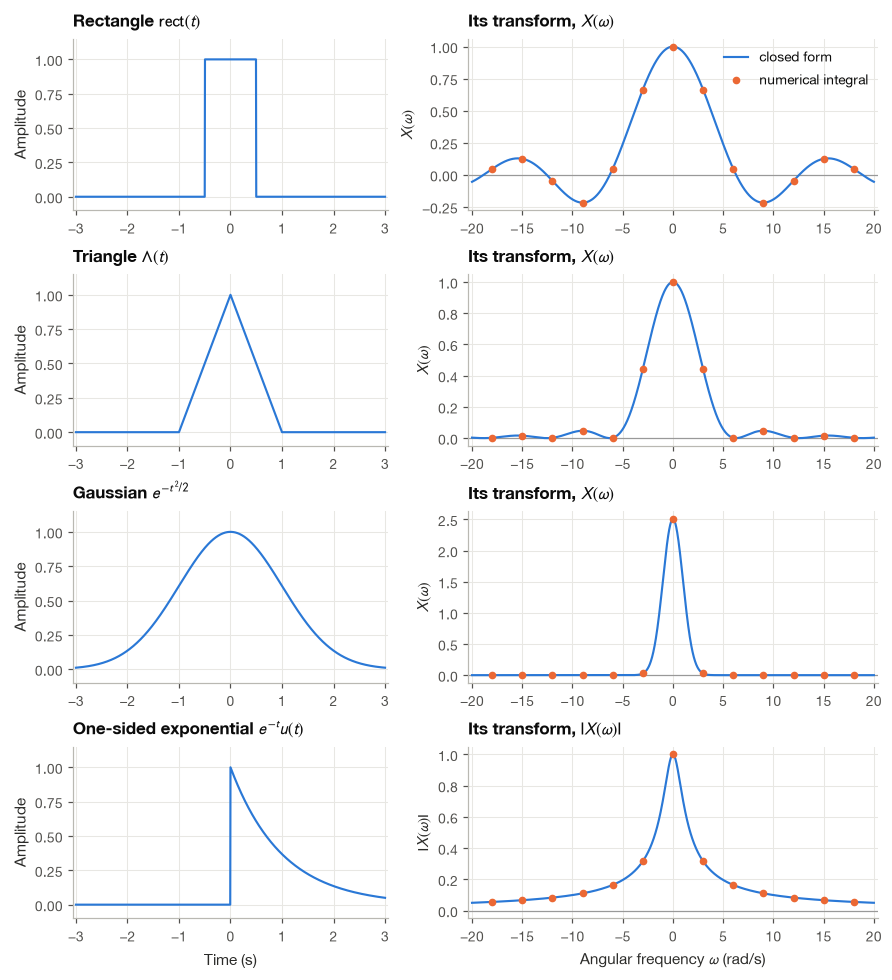

In [8]:
t = np.linspace(-3, 3, 1201)
w = np.linspace(-20, 20, 1601)
w_dots = np.linspace(-18, 18, 13)
show = [
    ("Rectangle $\\mathrm{rect}(t)$", lambda t: (np.abs(t) < 0.5) * 1.0, (-0.5, 0.5, None),
     lambda w: np.sinc(w / (2 * np.pi)), "$X(\\omega)$"),
    ("Triangle $\\Lambda(t)$", lambda t: np.clip(1 - np.abs(t), 0, None), (-1, 1, [0]),
     lambda w: np.sinc(w / (2 * np.pi))**2, "$X(\\omega)$"),
    ("Gaussian $e^{-t^2/2}$", lambda t: np.exp(-t**2 / 2), (-12, 12, None),
     lambda w: np.sqrt(2 * np.pi) * np.exp(-w**2 / 2), "$X(\\omega)$"),
    ("One-sided exponential $e^{-t}u(t)$", lambda t: np.exp(-t) * (t >= 0), (0, 40, None),
     lambda w: np.abs(1 / (1 + 1j * w)), "$|X(\\omega)|$"),
]
fig, axes = plt.subplots(4, 2, figsize=(8, 8.8), gridspec_kw={"width_ratios": [1, 1.3]})
for row, (name, x, (lo, hi, pts), Xw, ylab) in enumerate(show):
    axes[row, 0].plot(t, x(t), color=C[0])
    axes[row, 0].set(ylabel="Amplitude", title=name, ylim=(-0.1, 1.15))
    num = np.array([ctft(x, wd, lo, hi, pts) for wd in w_dots])
    num = np.abs(num) if "|" in ylab else num.real
    axes[row, 1].axhline(0, color="0.6", lw=0.8)
    axes[row, 1].plot(w, Xw(w), color=C[0], label="closed form")
    axes[row, 1].plot(w_dots, num, "o", color=C[1], ms=4, label="numerical integral")
    axes[row, 1].set(ylabel=ylab, title=f"Its transform, {ylab}")
axes[0, 1].legend(loc="upper right")
axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Angular frequency $\\omega$ (rad/s)")
plt.show()

## C.7 The DTFT and the DFT

### The discrete-time Fourier transform

$$
X(e^{j\Omega}) = \sum_{n=-\infty}^{\infty} x[n]\,e^{-j\Omega n}, \qquad
x[n] = \frac{1}{2\pi}\int_{-\pi}^{\pi} X(e^{j\Omega})\,e^{j\Omega n}\,d\Omega .
$$

$X(e^{j\Omega})$ is periodic in $\Omega$ with period $2\pi$; $\Omega = \pi$ corresponds to the Nyquist frequency $f_s/2$ (Chapter 10).

| Sequence $x[n]$ | DTFT $X(e^{j\Omega})$ | Condition |
|---|---|---|
| $\delta[n]$ | $1$ | |
| $\delta[n - n_0]$ | $e^{-j\Omega n_0}$ | |
| $a^n u[n]$ | $\dfrac{1}{1 - a e^{-j\Omega}}$ | $\lvert a\rvert < 1$ |
| $(n+1)\,a^n u[n]$ | $\dfrac{1}{(1 - a e^{-j\Omega})^2}$ | $\lvert a\rvert < 1$ |
| $a^{\lvert n\rvert}$ | $\dfrac{1 - a^2}{1 - 2a\cos\Omega + a^2}$ | $\lvert a\rvert < 1$, $a$ real |
| $1$ for $0 \le n \le N-1$, else $0$ | $e^{-j\Omega(N-1)/2}\,\dfrac{\sin(N\Omega/2)}{\sin(\Omega/2)}$ | |
| $1$ for $\lvert n\rvert \le M$, else $0$ | $\dfrac{\sin\big((2M+1)\Omega/2\big)}{\sin(\Omega/2)}$ | |
| $\dfrac{\sin(\Omega_c n)}{\pi n}$ | $1$ for $\lvert\Omega\rvert < \Omega_c$, $0$ for $\Omega_c < \lvert\Omega\rvert \le \pi$ | $0 < \Omega_c < \pi$ |
| $1$ | $2\pi\sum_{k}\delta(\Omega - 2\pi k)$ | |
| $e^{j\Omega_0 n}$ | $2\pi\sum_{k}\delta(\Omega - \Omega_0 - 2\pi k)$ | |
| $\cos(\Omega_0 n)$ | $\pi\sum_{k}\left[\delta(\Omega - \Omega_0 - 2\pi k) + \delta(\Omega + \Omega_0 - 2\pi k)\right]$ | |

| Property | Sequence | DTFT |
|---|---|---|
| Linearity | $a\,x[n] + b\,y[n]$ | $a\,X(e^{j\Omega}) + b\,Y(e^{j\Omega})$ |
| Time shift | $x[n - n_0]$ | $e^{-j\Omega n_0}X(e^{j\Omega})$ |
| Frequency shift | $e^{j\Omega_0 n}x[n]$ | $X(e^{j(\Omega - \Omega_0)})$ |
| Time reversal | $x[-n]$ | $X(e^{-j\Omega})$ |
| Conjugation | $x^*[n]$ | $X^*(e^{-j\Omega})$ |
| Real sequence | $x[n]$ real | $X(e^{-j\Omega}) = X^*(e^{j\Omega})$ |
| First difference | $x[n] - x[n-1]$ | $(1 - e^{-j\Omega})X(e^{j\Omega})$ |
| Multiplication by $n$ | $n\,x[n]$ | $j\,\dfrac{dX(e^{j\Omega})}{d\Omega}$ |
| Convolution | $x[n] * h[n]$ | $X(e^{j\Omega})\,H(e^{j\Omega})$ |
| Multiplication | $x[n]\,y[n]$ | $\frac{1}{2\pi}\int_{-\pi}^{\pi} X(e^{j\theta})\,Y(e^{j(\Omega - \theta)})\,d\theta$ |
| Parseval | $\sum_n \lvert x[n]\rvert^2$ | $= \frac{1}{2\pi}\int_{-\pi}^{\pi} \lvert X(e^{j\Omega})\rvert^2 d\Omega$ |

### The discrete Fourier transform

For a sequence of length $N$ (the convention of `np.fft.fft`):

$$
X[k] = \sum_{n=0}^{N-1} x[n]\,e^{-j2\pi kn/N}, \qquad
x[n] = \frac{1}{N}\sum_{k=0}^{N-1} X[k]\,e^{j2\pi kn/N}, \qquad k, n = 0, 1, \ldots, N-1 .
$$

Bin $k$ corresponds to the frequency $f_k = k f_s/N$ (bins $k > N/2$ represent the negative frequencies $(k - N) f_s/N$), and $X[k] = X(e^{j\Omega})$ evaluated at $\Omega = 2\pi k/N$. All shifts below are circular, written with the modulo index $((\cdot))_N$.

| Property or pair | Sequence (length $N$) | DFT |
|---|---|---|
| Impulse | $\delta[n]$ | $1$ |
| Constant | $1$ | $N\,\delta[k]$ |
| Complex exponential | $e^{j2\pi mn/N}$ | $N\,\delta[((k - m))_N]$ |
| Cosine | $\cos(2\pi mn/N)$, $0 < m < N/2$ | $\frac{N}{2}$ at $k = m$ and $k = N - m$, $0$ elsewhere |
| Circular time shift | $x[((n - m))_N]$ | $e^{-j2\pi km/N}X[k]$ |
| Circular frequency shift | $e^{j2\pi mn/N}x[n]$ | $X[((k - m))_N]$ |
| Circular time reversal | $x[((-n))_N]$ | $X[((-k))_N]$ |
| Conjugation | $x^*[n]$ | $X^*[((-k))_N]$ |
| Real sequence | $x[n]$ real | $X[N - k] = X^*[k]$ |
| Circular convolution | $\sum_{m=0}^{N-1} x[m]\,h[((n - m))_N]$ | $X[k]\,H[k]$ |
| Multiplication | $x[n]\,y[n]$ | $\frac{1}{N}\sum_{m=0}^{N-1} X[m]\,Y[((k - m))_N]$ |
| Sum and first sample | $X[0] = \sum_n x[n]$ | $x[0] = \frac{1}{N}\sum_k X[k]$ |
| Parseval | $\sum_{n} \lvert x[n]\rvert^2$ | $= \frac{1}{N}\sum_{k} \lvert X[k]\rvert^2$ |

Linear convolution of sequences of lengths $N_x$ and $N_h$ has length $N_x + N_h - 1$; computing it with the DFT requires zero-padding both sequences to at least that length, otherwise the result wraps around (time-domain aliasing).

In [9]:
g = "DTFT and DFT"
W = np.linspace(-np.pi, np.pi, 41)


def dtft(x, n, W):
    """DTFT of samples x at indices n, evaluated at the frequencies W."""
    return np.exp(-1j * np.outer(W, n)) @ x


n = np.arange(600)
a = 0.8
check(g, "a^n u[n]", dtft(a**n, n, W), 1 / (1 - a * np.exp(-1j * W)))
check(g, "(n+1) a^n u[n]", dtft((n + 1) * a**n, n, W), 1 / (1 - a * np.exp(-1j * W))**2)
n2 = np.arange(-300, 301)
check(g, "a^|n|", dtft(a**np.abs(n2), n2, W), (1 - a**2) / (1 - 2 * a * np.cos(W) + a**2))
Wnz = W[np.abs(W) > 1e-9]
N, Mh = 9, 4
check(g, "rectangle 0..N-1", dtft(np.ones(N), np.arange(N), Wnz),
      np.exp(-1j * Wnz * (N - 1) / 2) * np.sin(N * Wnz / 2) / np.sin(Wnz / 2))
check(g, "symmetric rectangle", dtft(np.ones(2 * Mh + 1), np.arange(-Mh, Mh + 1), Wnz),
      np.sin((2 * Mh + 1) * Wnz / 2) / np.sin(Wnz / 2))
check(g, "delta[n - n0]", dtft(np.array([1.0]), np.array([5]), W), np.exp(-5j * W))
Wc = 1.1
ideal = [integrate.quad(lambda w: np.cos(w * k) / (2 * np.pi), -Wc, Wc)[0] for k in range(1, 6)]
check(g, "ideal low-pass", ideal, np.sin(Wc * np.arange(1, 6)) / (np.pi * np.arange(1, 6)))
check(g, "ideal low-pass, n = 0", integrate.quad(lambda w: 1 / (2 * np.pi), -Wc, Wc)[0], Wc / np.pi)

x = rng.normal(size=12) + 1j * rng.normal(size=12)
y = rng.normal(size=7)
nx = np.arange(12)
X = lambda W: dtft(x, nx, W)
check(g, "time shift", dtft(x, nx + 3, W), np.exp(-3j * W) * X(W))
check(g, "frequency shift", dtft(np.exp(0.7j * nx) * x, nx, W), X(W - 0.7))
check(g, "time reversal", dtft(x, -nx, W), X(-W))
check(g, "conjugation", dtft(np.conj(x), nx, W), np.conj(X(-W)))
check(g, "first difference", dtft(np.convolve(x, [1, -1]), np.arange(13), W), (1 - np.exp(-1j * W)) * X(W))
check(g, "multiplication by n", dtft(nx * x, nx, W), 1j * (X(W + 1e-5) - X(W - 1e-5)) / 2e-5, tol=1e-6)
check(g, "convolution", dtft(np.convolve(x, y), np.arange(18), W), X(W) * dtft(y, np.arange(7), W))
Wg = 2 * np.pi * np.arange(64) / 64                 # exact for a trigonometric polynomial of degree < 64
check(g, "Parseval (DTFT)", np.sum(np.abs(x)**2), np.mean(np.abs(X(Wg))**2))

N = 16
n = np.arange(N)
xr = rng.normal(size=N)
hr = rng.normal(size=N)
F = np.fft.fft
Xr = F(xr)
check(g, "DFT definition", Xr, np.exp(-2j * np.pi * np.outer(n, n) / N) @ xr)
check(g, "inverse DFT", np.fft.ifft(Xr), xr)
check(g, "DFT samples the DTFT", Xr, dtft(xr, n, 2 * np.pi * n / N))
check(g, "DFT pairs", [F(n == 0), F(np.ones(N)), F(np.exp(2j * np.pi * 3 * n / N)), F(np.cos(2 * np.pi * 3 * n / N))],
      [np.ones(N), N * (n == 0), N * (n == 3), N / 2 * ((n == 3) | (n == N - 3))])
check(g, "circular shift", F(np.roll(xr, 5)), np.exp(-2j * np.pi * n * 5 / N) * Xr)
check(g, "circular frequency shift", F(np.exp(2j * np.pi * 5 * n / N) * xr), np.roll(Xr, 5))
check(g, "circular reversal", F(xr[(-n) % N]), Xr[(-n) % N])
check(g, "conjugate symmetry", Xr[(N - n) % N], np.conj(Xr))
circ = np.array([np.sum(xr * hr[(k - n) % N]) for k in range(N)])
check(g, "circular convolution", F(circ), Xr * F(hr))
Hr = F(hr)
check(g, "multiplication", F(xr * hr), np.array([np.sum(Xr * Hr[(k - n) % N]) for k in range(N)]) / N)
check(g, "Parseval (DFT)", np.sum(xr**2), np.sum(np.abs(Xr)**2) / N)
L = xr.size + y.size - 1
check(g, "linear convolution via zero-padded FFT", np.fft.ifft(F(xr, L) * F(y, L)).real, np.convolve(xr, y))
summarize(g)

DTFT and DFT: 28 formulas checked, largest absolute error 9.1e-08


## C.8 The Laplace Transform

$$
X(s) = \int_{-\infty}^{\infty} x(t)\,e^{-st}\,dt, \qquad s = \sigma + j\omega .
$$

For causal signals this coincides with the unilateral transform $\int_{0^-}^{\infty}$. The Fourier transform is $X(s)$ evaluated on the imaginary axis, $X(\omega) = X(s)\rvert_{s = j\omega}$, whenever the region of convergence (ROC) contains that axis. A causal LTI system is BIBO stable if and only if all poles of $H(s)$ lie in the open left half-plane.

| Signal | $X(s)$ | ROC |
|---|---|---|
| $\delta(t)$ | $1$ | all $s$ |
| $u(t)$ | $\dfrac{1}{s}$ | $\operatorname{Re}\{s\} > 0$ |
| $t\,u(t)$ | $\dfrac{1}{s^2}$ | $\operatorname{Re}\{s\} > 0$ |
| $t^n u(t)$ | $\dfrac{n!}{s^{n+1}}$ | $\operatorname{Re}\{s\} > 0$ |
| $e^{-at}u(t)$ | $\dfrac{1}{s + a}$ | $\operatorname{Re}\{s\} > -a$ |
| $-e^{-at}u(-t)$ | $\dfrac{1}{s + a}$ | $\operatorname{Re}\{s\} < -a$ |
| $t^n e^{-at}u(t)$ | $\dfrac{n!}{(s + a)^{n+1}}$ | $\operatorname{Re}\{s\} > -a$ |
| $\cos(\omega_0 t)\,u(t)$ | $\dfrac{s}{s^2 + \omega_0^2}$ | $\operatorname{Re}\{s\} > 0$ |
| $\sin(\omega_0 t)\,u(t)$ | $\dfrac{\omega_0}{s^2 + \omega_0^2}$ | $\operatorname{Re}\{s\} > 0$ |
| $e^{-at}\cos(\omega_0 t)\,u(t)$ | $\dfrac{s + a}{(s + a)^2 + \omega_0^2}$ | $\operatorname{Re}\{s\} > -a$ |
| $e^{-at}\sin(\omega_0 t)\,u(t)$ | $\dfrac{\omega_0}{(s + a)^2 + \omega_0^2}$ | $\operatorname{Re}\{s\} > -a$ |

| Property | Signal | Transform |
|---|---|---|
| Linearity | $a\,x(t) + b\,y(t)$ | $a\,X(s) + b\,Y(s)$ |
| Time shift | $x(t - t_0)\,u(t - t_0)$, $t_0 > 0$ | $e^{-st_0}X(s)$ |
| Shift in $s$ | $e^{-at}x(t)$ | $X(s + a)$ |
| Differentiation (unilateral) | $\dfrac{dx}{dt}$ | $sX(s) - x(0^-)$ |
| Second derivative (unilateral) | $\dfrac{d^2x}{dt^2}$ | $s^2X(s) - s\,x(0^-) - x'(0^-)$ |
| Integration | $\int_{0^-}^{t} x(\tau)\,d\tau$ | $\dfrac{X(s)}{s}$ |
| Convolution | $x(t) * h(t)$ | $X(s)\,H(s)$ |
| Initial value | $x(0^+)$ | $\lim_{s\to\infty} sX(s)$ (if $X(s)$ is strictly proper) |
| Final value | $\lim_{t\to\infty} x(t)$ | $\lim_{s\to 0} sX(s)$ (if all poles of $sX(s)$ have negative real part) |

In [10]:
g = "Laplace transform"


def laplace(x, s, lo=0.0, hi=80.0):
    """X(s) = integral of x(t) exp(-s t) over [lo, hi] by quadrature (real and imaginary parts)."""
    kw = dict(limit=400, epsabs=1e-12, epsrel=1e-11)
    re = integrate.quad(lambda t: (x(t) * np.exp(-s * t)).real, lo, hi, **kw)[0]
    im = integrate.quad(lambda t: (x(t) * np.exp(-s * t)).imag, lo, hi, **kw)[0]
    return re + 1j * im


a, w0 = 0.8, 2.5
for s in (1.5 + 2j, 0.4 - 1j, 3.0 + 0j):
    pairs = {
        "u(t)": (lambda t: 1.0, 1 / s),
        "t u(t)": (lambda t: t, 1 / s**2),
        "t^3 u(t)": (lambda t: t**3, 6 / s**4),
        "e^(-at) u(t)": (lambda t: np.exp(-a * t), 1 / (s + a)),
        "t^2 e^(-at) u(t)": (lambda t: t**2 * np.exp(-a * t), 2 / (s + a)**3),
        "cos u(t)": (lambda t: np.cos(w0 * t), s / (s**2 + w0**2)),
        "sin u(t)": (lambda t: np.sin(w0 * t), w0 / (s**2 + w0**2)),
        "damped cos": (lambda t: np.exp(-a * t) * np.cos(w0 * t), (s + a) / ((s + a)**2 + w0**2)),
        "damped sin": (lambda t: np.exp(-a * t) * np.sin(w0 * t), w0 / ((s + a)**2 + w0**2)),
    }
    for name, (x, Xs) in pairs.items():
        check(g, name, laplace(x, s, hi=150 if s.real < 1 else 80), Xs, tol=1e-7)
s_left = -1.5 + 2j                                     # inside the ROC Re{s} < -a of the anticausal pair
check(g, "-e^(-at) u(-t)", laplace(lambda t: -np.exp(-a * t), s_left, lo=-80, hi=0), 1 / (s_left + a))

s = 1.2 + 0.7j
x = lambda t: np.exp(-a * t) * np.cos(w0 * t)          # smooth for all t, x(0) = 1
dx = lambda t: -a * x(t) - w0 * np.exp(-a * t) * np.sin(w0 * t)
X = (s + a) / ((s + a)**2 + w0**2)
check(g, "differentiation", laplace(dx, s), s * X - 1)
check(g, "integration", laplace(lambda t: integrate.quad(x, 0, t)[0], s, hi=40), X / s, tol=1e-7)
t0 = 1.5
check(g, "time shift", laplace(lambda t: x(t - t0) * (t >= t0), s, lo=t0), np.exp(-s * t0) * X)
check(g, "convolution", laplace(lambda t: np.exp(-t) - np.exp(-2 * t), s), 1 / (s + 1) * 1 / (s + 2))
Xstep = lambda s: 1 / s - 1 / (s + a)                  # x(t) = 1 - e^(-at): x(0+) = 0, x(inf) = 1
check(g, "initial and final value", [1e9 * Xstep(1e9), 1e-9 * Xstep(1e-9)], [0, 1], tol=1e-8)
summarize(g)

Laplace transform: 33 formulas checked, largest absolute error 1.3e-09


## C.9 The Z-Transform

$$
X(z) = \sum_{n=-\infty}^{\infty} x[n]\,z^{-n} .
$$

The DTFT is $X(z)$ on the unit circle, $X(e^{j\Omega}) = X(z)\rvert_{z = e^{j\Omega}}$, whenever the ROC contains $\lvert z\rvert = 1$. A causal LTI system is BIBO stable if and only if all poles of $H(z)$ lie strictly inside the unit circle (Section 11.3).

| Sequence | $X(z)$ | ROC |
|---|---|---|
| $\delta[n]$ | $1$ | all $z$ |
| $\delta[n - m]$, $m > 0$ | $z^{-m}$ | $z \ne 0$ |
| $u[n]$ | $\dfrac{1}{1 - z^{-1}}$ | $\lvert z\rvert > 1$ |
| $a^n u[n]$ | $\dfrac{1}{1 - a z^{-1}}$ | $\lvert z\rvert > \lvert a\rvert$ |
| $-a^n u[-n-1]$ | $\dfrac{1}{1 - a z^{-1}}$ | $\lvert z\rvert < \lvert a\rvert$ |
| $n\,a^n u[n]$ | $\dfrac{a z^{-1}}{(1 - a z^{-1})^2}$ | $\lvert z\rvert > \lvert a\rvert$ |
| $(n+1)\,a^n u[n]$ | $\dfrac{1}{(1 - a z^{-1})^2}$ | $\lvert z\rvert > \lvert a\rvert$ |
| $1$ for $0 \le n \le N-1$, else $0$ | $\dfrac{1 - z^{-N}}{1 - z^{-1}}$ | $z \ne 0$ |
| $\cos(\Omega_0 n)\,u[n]$ | $\dfrac{1 - \cos\Omega_0\, z^{-1}}{1 - 2\cos\Omega_0\, z^{-1} + z^{-2}}$ | $\lvert z\rvert > 1$ |
| $\sin(\Omega_0 n)\,u[n]$ | $\dfrac{\sin\Omega_0\, z^{-1}}{1 - 2\cos\Omega_0\, z^{-1} + z^{-2}}$ | $\lvert z\rvert > 1$ |
| $r^n\cos(\Omega_0 n)\,u[n]$ | $\dfrac{1 - r\cos\Omega_0\, z^{-1}}{1 - 2r\cos\Omega_0\, z^{-1} + r^2 z^{-2}}$ | $\lvert z\rvert > r$ |
| $r^n\sin(\Omega_0 n)\,u[n]$ | $\dfrac{r\sin\Omega_0\, z^{-1}}{1 - 2r\cos\Omega_0\, z^{-1} + r^2 z^{-2}}$ | $\lvert z\rvert > r$ |

| Property | Sequence | $X(z)$ |
|---|---|---|
| Linearity | $a\,x[n] + b\,y[n]$ | $a\,X(z) + b\,Y(z)$ |
| Time shift | $x[n - m]$ | $z^{-m}X(z)$ |
| Unilateral shift by one | $x[n-1]$, $n \ge 0$ | $z^{-1}X_1(z) + x[-1]$ |
| Unilateral shift by two | $x[n-2]$, $n \ge 0$ | $z^{-2}X_1(z) + x[-1]\,z^{-1} + x[-2]$ |
| Scaling in $z$ | $a^n x[n]$ | $X(z/a)$ |
| Multiplication by $n$ | $n\,x[n]$ | $-z\,\dfrac{dX(z)}{dz}$ |
| Time reversal | $x[-n]$ | $X(1/z)$ |
| Conjugation | $x^*[n]$ | $X^*(z^*)$ |
| Convolution | $x[n] * h[n]$ | $X(z)\,H(z)$ |
| First difference | $x[n] - x[n-1]$ | $(1 - z^{-1})X(z)$ |
| Accumulation | $\sum_{k=-\infty}^{n} x[k]$ | $\dfrac{X(z)}{1 - z^{-1}}$ |
| Initial value (causal $x$) | $x[0]$ | $\lim_{z\to\infty} X(z)$ |
| Final value | $\lim_{n\to\infty} x[n]$ | $\lim_{z\to 1}(1 - z^{-1})X(z)$ (if the poles of $(1 - z^{-1})X(z)$ are inside the unit circle) |

Here $X_1(z) = \sum_{n=0}^{\infty} x[n]z^{-n}$ is the unilateral transform, used to solve difference equations with initial conditions ([Section 5.5](../ch05_convolution/index.md)). The rational pairs connect directly to `scipy.signal.lfilter`: the impulse response of the filter with numerator `b` and denominator `a` is the inverse z-transform of $B(z)/A(z)$.

In [11]:
g = "Z-transform"


def ztrans(x, n, z):
    """Truncated z-transform: sum of x[n] z^(-n) over the given indices."""
    return np.sum(x * z**(-n.astype(float)))


n = np.arange(400)
a, r, W0 = 0.8, 0.9, 0.7
z = 1.3 * np.exp(0.7j)                                 # |z| > 1 > r > a
pairs = {
    "u[n]": (np.ones(n.size), 1 / (1 - 1 / z)),
    "a^n u[n]": (a**n, 1 / (1 - a / z)),
    "n a^n u[n]": (n * a**n, (a / z) / (1 - a / z)**2),
    "(n+1) a^n u[n]": ((n + 1) * a**n, 1 / (1 - a / z)**2),
    "cos u[n]": (np.cos(W0 * n), (1 - np.cos(W0) / z) / (1 - 2 * np.cos(W0) / z + z**-2)),
    "sin u[n]": (np.sin(W0 * n), (np.sin(W0) / z) / (1 - 2 * np.cos(W0) / z + z**-2)),
    "r^n cos u[n]": (r**n * np.cos(W0 * n), (1 - r * np.cos(W0) / z) / (1 - 2 * r * np.cos(W0) / z + r**2 / z**2)),
    "r^n sin u[n]": (r**n * np.sin(W0 * n), (r * np.sin(W0) / z) / (1 - 2 * r * np.cos(W0) / z + r**2 / z**2)),
}
for name, (x, Xz) in pairs.items():
    check(g, name, ztrans(x, n, z), Xz, tol=1e-9 if "u[n]" != name and "cos u" not in name and "sin u" not in name else 1e-8)
check(g, "delta[n - 3]", ztrans(np.array([1.0]), np.array([3]), z), z**-3)
check(g, "finite rectangle", ztrans(np.ones(9), np.arange(9), z), (1 - z**-9) / (1 - 1 / z))
a2 = 2.0                                               # anticausal pair, needs |z| < |a|
m = np.arange(-400, 0)
check(g, "-a^n u[-n-1]", ztrans(-a2**m, m, z), 1 / (1 - a2 / z))
imp = np.zeros(60)
imp[0] = 1
check(g, "lfilter impulse response", signal.lfilter([1, -r * np.cos(W0)], [1, -2 * r * np.cos(W0), r**2], imp),
      r**np.arange(60) * np.cos(W0 * np.arange(60)))

x = a**n                                               # x[n] = a^n for all n (needed for unilateral shifts)
X1 = 1 / (1 - a / z)
check(g, "time shift", ztrans(x, n + 4, z), z**-4 * X1)
check(g, "unilateral shift by one", ztrans(a**(n - 1.0), n, z), X1 / z + a**-1)
check(g, "unilateral shift by two", ztrans(a**(n - 2.0), n, z), X1 / z**2 + a**-1 / z + a**-2)
check(g, "scaling in z", ztrans((0.5**n) * x, n, z), 1 / (1 - a / (z / 0.5)))
Xf = lambda zz: 1 / (1 - a / zz)
h = 1e-6
check(g, "multiplication by n", ztrans(n * x, n, z), -z * (Xf(z + h) - Xf(z - h)) / (2 * h), tol=1e-6)
xf, nf = rng.normal(size=8), np.arange(8)
check(g, "time reversal", ztrans(xf, -nf, z), ztrans(xf, nf, 1 / z))
yf = rng.normal(size=5)
check(g, "convolution", ztrans(np.convolve(xf, yf), np.arange(12), z), ztrans(xf, nf, z) * ztrans(yf, np.arange(5), z))
check(g, "first difference", ztrans(np.convolve(xf, [1, -1]), np.arange(9), z), (1 - 1 / z) * ztrans(xf, nf, z))
check(g, "accumulation", ztrans(np.cumsum(x), n, z), X1 / (1 - 1 / z), tol=1e-8)
xs = 1 - a**n                                          # x[0] = 0, x[inf] = 1
Xs = lambda zz: 1 / (1 - 1 / zz) - 1 / (1 - a / zz)
check(g, "initial and final value", [Xs(1e9), (1 - 1 / (1 + 1e-9)) * Xs(1 + 1e-9)], [0, 1], tol=1e-6)
summarize(g)

Z-transform: 22 formulas checked, largest absolute error 5.0e-09


## C.10 Convolution

Continuous and discrete convolution are defined by

$$
y(t) = (x * h)(t) = \int_{-\infty}^{\infty} x(\tau)\,h(t - \tau)\,d\tau, \qquad
y[n] = (x * h)[n] = \sum_{k=-\infty}^{\infty} x[k]\,h[n - k] .
$$

| Property | Statement |
|---|---|
| Commutative | $x * h = h * x$ |
| Associative | $(x * h_1) * h_2 = x * (h_1 * h_2)$ (systems in series) |
| Distributive | $x * (h_1 + h_2) = x * h_1 + x * h_2$ (systems in parallel) |
| Identity | $x * \delta = x$ |
| Shift | $x(t) * \delta(t - t_0) = x(t - t_0)$; if $y = x * h$, then $x(t - t_1) * h(t - t_2) = y(t - t_1 - t_2)$ |
| Differentiation | $\dfrac{d}{dt}(x * h) = \dfrac{dx}{dt} * h = x * \dfrac{dh}{dt}$ |
| Area | $\int (x * h)\,dt = \left(\int x\,dt\right)\left(\int h\,dt\right)$; $\sum_n (x * h)[n] = \sum_n x[n] \sum_n h[n]$ |
| Duration | lengths $N_x$ and $N_h$ give length $N_x + N_h - 1$; supports $[a_1, b_1]$ and $[a_2, b_2]$ give $[a_1 + a_2,\ b_1 + b_2]$ |
| Step response | $s(t) = \int_{-\infty}^{t} h(\tau)\,d\tau$, $\quad s[n] = \sum_{k=-\infty}^{n} h[k]$ |
| Causality of an LTI system | $h(t) = 0$ for $t < 0$; $h[n] = 0$ for $n < 0$ |
| BIBO stability of an LTI system | $\int \lvert h(t)\rvert\,dt < \infty$; $\sum_n \lvert h[n]\rvert < \infty$ |
| Gaussians | $e^{-t^2/(2\sigma_1^2)} * e^{-t^2/(2\sigma_2^2)} = \dfrac{\sqrt{2\pi}\,\sigma_1\sigma_2}{\sigma}\,e^{-t^2/(2\sigma^2)}$, $\sigma^2 = \sigma_1^2 + \sigma_2^2$ |
| Transforms | $x * h \leftrightarrow X H$ for the Fourier, Laplace and z-transforms; circular convolution $\leftrightarrow X[k]H[k]$ for the DFT |

In [12]:
g = "Convolution"
x, h1, h2 = rng.normal(size=20), rng.normal(size=9), rng.normal(size=9)
cv = np.convolve
check(g, "commutative", cv(x, h1), cv(h1, x))
check(g, "associative", cv(cv(x, h1), h2), cv(x, cv(h1, h2)))
check(g, "distributive", cv(x, h1 + h2), cv(x, h1) + cv(x, h2))
check(g, "identity", cv(x, [1.0]), x)
check(g, "shift by delta[n-3]", cv(x, [0, 0, 0, 1.0]), np.r_[0, 0, 0, x])
check(g, "length N + M - 1", cv(x, h1).size, x.size + h1.size - 1)
check(g, "sum property", cv(x, h1).sum(), x.sum() * h1.sum())
check(g, "step response = running sum", signal.lfilter(h1, [1.0], np.ones(15)), np.cumsum(np.r_[h1, np.zeros(6)])[:15])
dt = 1e-3
t = np.arange(-8, 8 + dt / 2, dt)
s1, s2 = 0.3, 0.4
s12 = np.hypot(s1, s2)
g1, g2 = np.exp(-t**2 / (2 * s1**2)), np.exp(-t**2 / (2 * s2**2))
num = cv(g1, g2, mode="same") * dt
closed = np.sqrt(2 * np.pi) * s1 * s2 / s12 * np.exp(-t**2 / (2 * s12**2))
check(g, "Gaussian convolution", num, closed, tol=1e-9)
dg1 = -t / s1**2 * g1
check(g, "differentiation", cv(dg1, g2, mode="same") * dt, -t / s12**2 * closed, tol=1e-8)
summarize(g)

Convolution: 10 formulas checked, largest absolute error 6.4e-12


## C.11 Probability and Statistics

### Definitions

For a continuous random variable $X$ with probability density function (PDF) $p(x)$ and cumulative distribution function (CDF) $F(x)$,

$$
\begin{aligned}
&p(x) \ge 0, \qquad \int_{-\infty}^{\infty} p(x)\,dx = 1, \qquad F(x) = P(X \le x) = \int_{-\infty}^{x} p(\xi)\,d\xi, \qquad P(a < X \le b) = F(b) - F(a),\\
&\mu = \mathbb{E}[X] = \int x\,p(x)\,dx, \qquad \mathbb{E}[g(X)] = \int g(x)\,p(x)\,dx, \qquad
\sigma^2 = \mathbb{E}\left[(X - \mu)^2\right] = \mathbb{E}[X^2] - \mu^2,\\
&\text{skewness } \gamma_1 = \frac{\mathbb{E}\left[(X - \mu)^3\right]}{\sigma^3}, \qquad
\text{kurtosis } \beta_2 = \frac{\mathbb{E}\left[(X - \mu)^4\right]}{\sigma^4} \quad (\beta_2 = 3 \text{ for a Gaussian; excess kurtosis } \beta_2 - 3).
\end{aligned}
$$

### Linear combinations, covariance and correlation

$$
\begin{aligned}
&\mathbb{E}[aX + b] = a\mu + b, \qquad \operatorname{Var}(aX + b) = a^2\sigma^2,\\
&\operatorname{Cov}(X, Y) = \mathbb{E}\left[(X - \mu_X)(Y - \mu_Y)\right] = \mathbb{E}[XY] - \mu_X\mu_Y, \qquad
\rho_{XY} = \frac{\operatorname{Cov}(X, Y)}{\sigma_X\sigma_Y}, \quad -1 \le \rho_{XY} \le 1,\\
&\operatorname{Var}(X + Y) = \sigma_X^2 + \sigma_Y^2 + 2\operatorname{Cov}(X, Y), \qquad
\operatorname{Var}(\mathbf{a}^T\mathbf{x}) = \mathbf{a}^T\mathbf{C}\,\mathbf{a}, \quad \mathbf{C} = \mathbb{E}\left[(\mathbf{x} - \boldsymbol{\mu})(\mathbf{x} - \boldsymbol{\mu})^T\right].
\end{aligned}
$$

Independent variables are uncorrelated, but uncorrelated variables need not be independent: for $X$ symmetric about zero, $Y = X^2$ is completely determined by $X$ yet $\operatorname{Cov}(X, Y) = \mathbb{E}[X^3] = 0$. If $X$ and $Y$ are independent, the PDF of $X + Y$ is the convolution $p_X * p_Y$, and their means and variances add. Bayes' rule reads $P(A \mid B) = P(B \mid A)\,P(A)/P(B)$, and Chebyshev's inequality $P(\lvert X - \mu\rvert \ge k\sigma) \le 1/k^2$ holds for any distribution with finite variance.

### Common distributions

| Distribution | PDF or probability mass | Mean | Variance | Skewness | Kurtosis $\beta_2$ |
|---|---|---|---|---|---|
| Uniform on $[a, b]$ | $\dfrac{1}{b - a}$ for $a \le x \le b$ | $\dfrac{a + b}{2}$ | $\dfrac{(b - a)^2}{12}$ | $0$ | $1.8$ |
| Gaussian $\mathcal{N}(\mu, \sigma^2)$ | $\dfrac{1}{\sigma\sqrt{2\pi}}\,e^{-(x - \mu)^2/(2\sigma^2)}$ | $\mu$ | $\sigma^2$ | $0$ | $3$ |
| Laplacian, scale $b$ | $\dfrac{1}{2b}\,e^{-\lvert x - \mu\rvert/b}$ | $\mu$ | $2b^2$ | $0$ | $6$ |
| Exponential, rate $\lambda$ | $\lambda e^{-\lambda x}$ for $x \ge 0$ | $\dfrac{1}{\lambda}$ | $\dfrac{1}{\lambda^2}$ | $2$ | $9$ |
| Rayleigh, scale $\sigma$ | $\dfrac{x}{\sigma^2}\,e^{-x^2/(2\sigma^2)}$ for $x \ge 0$ | $\sigma\sqrt{\pi/2}$ | $\dfrac{4 - \pi}{2}\,\sigma^2$ | $\dfrac{2\sqrt{\pi}(\pi - 3)}{(4 - \pi)^{3/2}} \approx 0.631$ | $\approx 3.245$ |
| Poisson, rate $\lambda$ | $P(k) = \dfrac{\lambda^k e^{-\lambda}}{k!}$, $k = 0, 1, \ldots$ | $\lambda$ | $\lambda$ | $\dfrac{1}{\sqrt{\lambda}}$ | $3 + \dfrac{1}{\lambda}$ |

For a Gaussian, $P(\lvert X - \mu\rvert < k\sigma) = \operatorname{erf}(k/\sqrt{2})$, which is 0.6827 for $k = 1$, 0.9545 for $k = 2$, 0.9973 for $k = 3$ and 0.9500 for $k = 1.960$. The multivariate Gaussian with mean $\boldsymbol{\mu}$ and covariance $\mathbf{C}$ in $d$ dimensions has density $(2\pi)^{-d/2}\det(\mathbf{C})^{-1/2}\exp\!\big(-\tfrac{1}{2}(\mathbf{x} - \boldsymbol{\mu})^T\mathbf{C}^{-1}(\mathbf{x} - \boldsymbol{\mu})\big)$. The Rayleigh distribution describes the envelope of narrowband Gaussian noise, and the Poisson distribution the number of events (for example neural spikes) in a fixed interval.

### Estimation from $N$ independent samples

$$
\begin{aligned}
&\bar{x} = \frac{1}{N}\sum_{n=1}^{N} x_n, \qquad \mathbb{E}[\bar{x}] = \mu, \qquad \operatorname{Var}(\bar{x}) = \frac{\sigma^2}{N}, \qquad
s^2 = \frac{1}{N - 1}\sum_{n=1}^{N}(x_n - \bar{x})^2, \qquad \mathbb{E}[s^2] = \sigma^2,\\
&\text{95\% confidence interval for } \mu: \;\; \bar{x} \pm 1.96\,\frac{\sigma}{\sqrt{N}} \;\; (\sigma \text{ known or } N \text{ large}), \qquad
\bar{x} \pm t_{0.975,\,N-1}\,\frac{s}{\sqrt{N}} \;\; (\text{small } N).
\end{aligned}
$$

The central limit theorem states that $(\bar{x} - \mu)/(\sigma/\sqrt{N})$ approaches a standard Gaussian as $N$ grows, whatever the distribution of the individual samples (provided its variance is finite). The variance formula $\sigma^2/N$ is the basis of signal averaging (Section 10.1).

### Noise models

Uniform quantization with step $\Delta$ produces an error that is approximately uniform on $[-\Delta/2, \Delta/2]$, with variance $\Delta^2/12$. For a full-scale sinusoid digitized with $B$ bits, the resulting signal-to-quantization-noise ratio is $\text{SQNR} \approx 6.02B + 1.76$ dB (Section 9.4). White Gaussian noise models thermal and amplifier noise, and the heavier-tailed Laplacian is a common model for impulsive noise and for EMG amplitudes.

In [13]:
g = "Probability"
Ns = 2_000_000
sig, b_lap, lam, ray = 1.3, 0.8, 2.0, 1.1
samples = {
    "uniform [-1, 2]": (rng.uniform(-1, 2, Ns), (0.5, 9 / 12, 0, 1.8)),
    "Gaussian": (rng.normal(0.4, sig, Ns), (0.4, sig**2, 0, 3)),
    "Laplacian": (rng.laplace(0, b_lap, Ns), (0, 2 * b_lap**2, 0, 6)),
    "exponential": (rng.exponential(1 / lam, Ns), (1 / lam, 1 / lam**2, 2, 9)),
    "Rayleigh": (rng.rayleigh(ray, Ns), (ray * np.sqrt(np.pi / 2), (4 - np.pi) / 2 * ray**2,
                                        2 * np.sqrt(np.pi) * (np.pi - 3) / (4 - np.pi)**1.5,
                                        3 - (6 * np.pi**2 - 24 * np.pi + 16) / (4 - np.pi)**2)),
    "Poisson": (rng.poisson(3.0, Ns).astype(float), (3.0, 3.0, 1 / np.sqrt(3), 3 + 1 / 3)),
}
for name, (x, (mu, var, skew, kurt)) in samples.items():
    m, v = x.mean(), x.var()
    z = (x - m) / np.sqrt(v)
    sk, ku = np.mean(z**3), np.mean(z**4)
    check(g, f"{name} moments", [m - mu, v / var - 1, sk - skew, (ku - kurt) / kurt], 0, tol=0.03)
check(g, "Rayleigh constants", [2 * np.sqrt(np.pi) * (np.pi - 3) / (4 - np.pi)**1.5,
                                3 - (6 * np.pi**2 - 24 * np.pi + 16) / (4 - np.pi)**2], [0.631, 3.245], tol=6e-4)
check(g, "Gaussian probabilities", special.erf(np.array([1, 2, 3, 1.959964]) / np.sqrt(2)),
      [0.6827, 0.9545, 0.9973, 0.9500], tol=5e-5)
check(g, "1.96 quantile", special.ndtri(0.975), 1.96, tol=5e-5)
N, trials = 25, 40_000
batch = rng.normal(0, sig, (trials, N))
check(g, "variance of the sample mean", batch.mean(axis=1).var() / (sig**2 / N), 1, tol=0.03)
check(g, "unbiased s^2 (ddof=1) vs biased", [batch.var(axis=1, ddof=1).mean() / sig**2,
                                              batch.var(axis=1, ddof=0).mean() / sig**2], [1, (N - 1) / N], tol=0.01)
xg = rng.normal(size=Ns)
check(g, "uncorrelated but dependent (y = x^2)", np.cov(xg, xg**2)[0, 1], 0, tol=0.01)
yg = 0.6 * xg + rng.normal(size=Ns)
check(g, "Var(X + Y) identity", np.var(xg + yg), np.var(xg) + np.var(yg) + 2 * np.cov(xg, yg, ddof=0)[0, 1], tol=1e-9)
delta = 0.01
u = rng.uniform(-3, 3, Ns)
check(g, "quantization noise variance", np.var(delta * np.round(u / delta) - u) / (delta**2 / 12), 1, tol=0.01)
B = 12
tq = np.arange(200_000)
sine = np.sin(2 * np.pi * 0.012345 * tq)
q = 2 / 2**B
sqnr = 10 * np.log10(np.var(sine) / np.var(q * np.round(sine / q) - sine))
check(g, "SQNR = 6.02 B + 1.76 dB", sqnr, 6.02 * B + 1.76, tol=0.2)
summarize(g)
print(f"(SQNR of a full-scale sine at {B} bits: {sqnr:.2f} dB, formula {6.02 * B + 1.76:.2f} dB)")

Probability: 15 formulas checked, largest absolute error 3.1e-02
(SQNR of a full-scale sine at 12 bits: 74.03 dB, formula 74.00 dB)


The figure compares three noise densities that appear throughout the book, all scaled to unit variance, with histograms of simulated samples. On the logarithmic axis the Gaussian density is a parabola, the Laplacian a pair of straight lines, and the uniform a flat top with hard edges. The Laplacian's heavier tails are what its kurtosis of 6 measures.

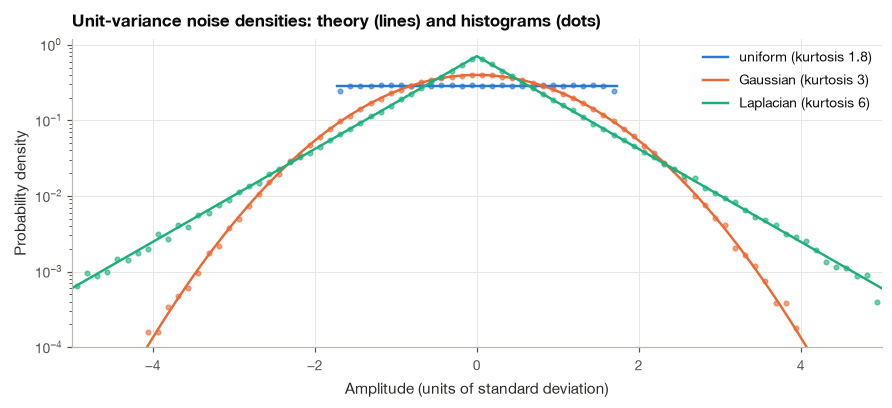

In [14]:
xs = np.linspace(-5, 5, 1001)
bl = 1 / np.sqrt(2)                                     # Laplacian scale for unit variance
w_u = np.sqrt(3)                                        # uniform half-width for unit variance
dens = {
    "uniform": (np.where(np.abs(xs) <= w_u, 1 / (2 * w_u), np.nan), rng.uniform(-w_u, w_u, 400_000)),
    "Gaussian": (np.exp(-xs**2 / 2) / np.sqrt(2 * np.pi), rng.normal(0, 1, 400_000)),
    "Laplacian": (np.exp(-np.abs(xs) / bl) / (2 * bl), rng.laplace(0, bl, 400_000)),
}
edges = np.linspace(-5, 5, 81)
centers = (edges[:-1] + edges[1:]) / 2
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, (name, (pdf, smp)) in enumerate(dens.items()):
    hist, _ = np.histogram(smp, bins=edges, density=True)
    ax.plot(centers[hist > 0], hist[hist > 0], "o", color=C[i], ms=3, alpha=0.6)
    ax.plot(xs, pdf, color=C[i], lw=1.6, label=f"{name} (kurtosis {[1.8, 3, 6][i]})")
ax.set_yscale("log")
ax.set(xlim=(-5, 5), ylim=(1e-4, 1.2), xlabel="Amplitude (units of standard deviation)",
       ylabel="Probability density", title="Unit-variance noise densities: theory (lines) and histograms (dots)")
ax.legend(loc="upper right")
plt.show()

## C.12 Decibels

A ratio of powers $P_1/P_2$ is expressed in decibels as $10\log_{10}(P_1/P_2)$, and a ratio of amplitudes (voltages, RMS values, magnitudes of a frequency response) as $20\log_{10}(A_1/A_2)$. The two agree because power is proportional to amplitude squared. To convert back, use $10^{\text{dB}/10}$ for a power ratio and $10^{\text{dB}/20}$ for an amplitude ratio.

| Ratio | As an amplitude ratio (dB) | As a power ratio (dB) |
|---|---|---|
| 0.001 | −60 | −30 |
| 0.01 | −40 | −20 |
| 0.1 | −20 | −10 |
| 0.5 | −6.02 | −3.01 |
| $1/\sqrt{2} \approx 0.707$ | −3.01 | −1.51 |
| 1 | 0 | 0 |
| $\sqrt{2} \approx 1.414$ | 3.01 | 1.51 |
| 2 | 6.02 | 3.01 |
| 10 | 20 | 10 |
| 100 | 40 | 20 |
| 1000 | 60 | 30 |

A few facts follow directly and are used constantly. The cutoff frequency of a filter is usually defined at −3 dB, where the amplitude has fallen to $1/\sqrt{2}$ of its passband value and the power to one half. A first-order filter rolls off at 20 dB per decade of frequency, which is 6.02 dB per octave, and an $n$-th order filter at $20n$ dB per decade. The signal-to-noise ratio is $\text{SNR} = 10\log_{10}(P_s/P_n) = 20\log_{10}(\text{RMS}_s/\text{RMS}_n)$ (Section 3.4). Gains in dB add when systems are connected in series, but the powers of uncorrelated noise sources add in linear units, not in dB: two equal noise sources together are 3.01 dB stronger than one. A differential amplifier with a common-mode rejection ratio of 100 dB amplifies the ECG $10^5$ times more than the common-mode interference, and each additional bit of an ideal ADC improves the SQNR by 6.02 dB.

In [15]:
g = "Decibels"
ratios = np.array([0.001, 0.01, 0.1, 0.5, 1 / np.sqrt(2), 1, np.sqrt(2), 2, 10, 100, 1000])
amp_db = [-60, -40, -20, -6.02, -3.01, 0, 3.01, 6.02, 20, 40, 60]
pow_db = [-30, -20, -10, -3.01, -1.51, 0, 1.51, 3.01, 10, 20, 30]
check(g, "amplitude ratios", np.round(20 * np.log10(ratios), 2), amp_db, tol=1e-12)
check(g, "power ratios", np.round(10 * np.log10(ratios), 2), pow_db, tol=1e-12)
check(g, "round trip", [10**(20 * np.log10(2) / 20), 10**(10 * np.log10(2) / 10)], [2, 2])
check(g, "6.02 dB per octave", 20 * np.log10(2), 6.02, tol=6e-4)
check(g, "two equal noise sources", 10 * np.log10(2), 3.01, tol=6e-4)
check(g, "CMRR 100 dB", 10**(100 / 20), 1e5, tol=1e-6)
summarize(g)

table = (pd.DataFrame(RESULTS, columns=["group", "formula", "error", "tol"])
         .groupby("group", sort=False)
         .agg(formulas=("formula", "size"), largest_error=("error", "max")))
print(f"\nAll {len(RESULTS)} checks passed.")
print(table.to_string(formatters={"largest_error": "{:.1e}".format}))

Decibels: 6 formulas checked, largest absolute error 6.0e-04

All 239 checks passed.
                        formulas largest_error
group                                         
Trigonometry and Euler        24       7.9e-15
Series and sums               22       4.3e-14
Integrals                     38       1.6e-06
Fourier series                 6       1.2e-05
Fourier transform             35       6.3e-07
DTFT and DFT                  28       9.1e-08
Laplace transform             33       1.3e-09
Z-transform                   22       5.0e-09
Convolution                   10       6.4e-12
Probability                   15       3.1e-02
Decibels                       6       6.0e-04


## Exercises

1. Starting from the infinite geometric series, derive the DTFT pair $a^{\lvert n\rvert} \leftrightarrow (1 - a^2)/(1 - 2a\cos\Omega + a^2)$ by splitting the sum into $n \ge 0$ and $n < 0$. Then evaluate both sides in Python for $a = 0.5$ at a few frequencies.
2. Use the table of Laplace pairs and partial fractions to find the inverse transform of $X(s) = \dfrac{3s + 5}{(s + 1)(s + 2)}$ for a causal signal. Check your answer with the initial and final value theorems, and numerically by evaluating $\int_0^\infty x(t)\,e^{-st}\,dt$ at $s = 1$.
3. Using the properties table, show that the Fourier transform of $x(t) = t\,e^{-t^2/2}$ is $-j\sqrt{2\pi}\,\omega\,e^{-\omega^2/2}$ in two different ways: with the multiplication-by-$t$ property and with the differentiation property. Confirm the result by numerical integration.

## Further Reading

The transform tables follow the conventions of {cite:t}`oppenheim1997` for continuous-time signals and {cite:t}`oppenheim2010` for discrete-time signals, and {cite:t}`lathi2018` contains extensive tables of Laplace and Fourier pairs with worked derivations. {cite:t}`proakis2007` is a good second source for the DFT and z-transform properties. The probability formulas and distributions are treated in depth by {cite:t}`papoulis2002`, and the linear algebra behind covariance matrices by {cite:t}`strang2016`.